<a href="https://colab.research.google.com/github/anix07/Eco-Move-Mobility/blob/main/EcoMoveMobility.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

IMPORTING LIBRARIES

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

In [ ]:
df = pd.read_excel('/content/[5442] EcoMoveMobility.xlsx')
display(df.head())

,Record_ID,Date,City,Country,Transport_Mode,Route_Type,Weather,Event_Day,Passengers,Trips,Average_Delay_Minutes,On_Time_Percentage,Ticket_Revenue_EUR,Operating_Cost_EUR,CO2_Saved_KG,Energy_Consumption_KWh,Customer_Rating,Accessibility_Complaints
0,EM-00001,45747,Paris,France,Tram,Tourist Zone,Cloudy,Yes,22946,101,3.2,85.1,58846.34,47796.73,2005.0,1446.4,4.4,26
1,EM-00002,45717,Paris,France,Tram,University Area,Cloudy,No,9417,59,1.5,90.1,24578.85,20708.01,824.3,495.1,4.7,7
2,EM-00003,45882,Rotterdam,Netherlands,Tram,Airport Connector,Clear,No,6467,38,3.4,87.9,15168.68,14129.41,693.1,405.8,4.4,7
3,EM-00004,45504,Lyon,France,Tram,University Area,Clear,Yes,5218,33,6.9,74.5,14172.20,11945.52,600.1,278.1,3.9,7
4,EM-00005,45578,Amsterdam,Netherlands,Metro,Tourist Zone,Cloudy,No,10258,19,3.6,83.2,27534.92,28846.82,1392.4,580.5,4.4,12


In [ ]:
# missing value
missing_summary = df.isnull().sum()
display(missing_summary)

,0
Record_ID,0
Date,0
City,0
Country,0
Transport_Mode,0
Route_Type,0
Weather,0
Event_Day,0
Passengers,0
Trips,0


In [ ]:
# Check the current data type and unique samples of the Date column
print(df['Date'].dtype)
print(df['Date'].head())

int64
0    45747
1    45717
2    45882
3    45504
4    45578
Name: Date, dtype: int64


In [ ]:
# Duplicates records
duplicate_rows = df[df.duplicated()]
print("Number of duplicate rows:", len(duplicate_rows))

Number of duplicate rows: 0


In [ ]:
# Convert the Date column to a clean datetime format
df['Date'] = pd.to_datetime(df['Date'])
display(df[['Date']].head())

,Date
0,1970-01-01 00:00:00.000045747
1,1970-01-01 00:00:00.000045717
2,1970-01-01 00:00:00.000045882
3,1970-01-01 00:00:00.000045504
4,1970-01-01 00:00:00.000045578


In [ ]:
# Calculate Managerial KPIs: Profit and Cost Recovery Ratio
df['Profit_EUR'] = df['Ticket_Revenue_EUR'] - df['Operating_Cost_EUR']
df['Cost_Recovery'] = df['Ticket_Revenue_EUR'] / df['Operating_Cost_EUR']

# Create log-transformed Passenger variable to prevent skewness in visualizations
df['Log_Passengers'] = np.log10(df['Passengers'])

# Display summary statistics of the new features
display(df[['Passengers', 'Log_Passengers', 'Ticket_Revenue_EUR', 'Operating_Cost_EUR', 'Profit_EUR', 'Cost_Recovery']].describe())

,Passengers,Log_Passengers,Ticket_Revenue_EUR,Operating_Cost_EUR,Profit_EUR,Cost_Recovery
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,8181.944200,3.525767,22328.122852,22422.003194,-93.880342,0.841245
std,10018.716968,0.682229,28822.411230,26114.317880,6022.603491,0.458246
min,64.000000,1.806180,90.930000,978.370000,-30923.780000,0.029599
25%,1411.750000,3.149757,3280.330000,7189.860000,-2721.770000,0.804359
50%,4398.000000,3.643255,11190.020000,11638.285000,306.740000,1.022583
75%,10077.500000,4.003353,26329.652500,22732.975000,2674.230000,1.150022
max,66416.000000,4.822273,204386.050000,178936.390000,31285.360000,1.588017


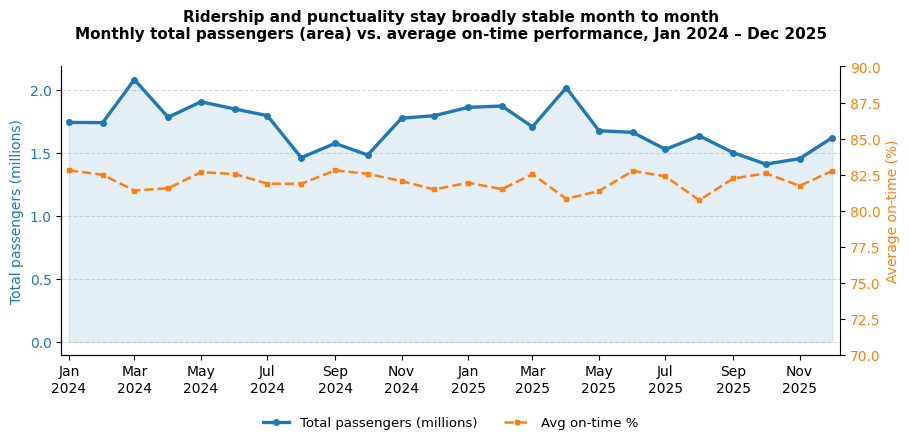

fig1 done (24, 4)


In [ ]:
"""FIG 1 - Time-series: monthly ridership trend with on-time reliability overlay."""

# Ensure output directory exists
os.makedirs("figs", exist_ok=True)

# 1. Reload the dataframe to get the raw integer serial dates back and fix the 1970 collapse
df = pd.read_excel('/content/[5442] EcoMoveMobility.xlsx')

# 2. Convert Excel serial dates correctly (Excel epoch starts on 1899-12-30)
df['Date'] = pd.to_datetime(df['Date'], unit='D', origin='1899-12-30')

# 3. Create 'Month' column (first day of each month for plotting)
df['Month'] = df['Date'].dt.to_period('M').dt.to_timestamp()

# Define the style constants that were previously imported from prep
ACCENT = '#1f77b4'  # Blue color for passengers
WARN = '#ff7f0e'    # Orange color for reliability

m = df.groupby("Month").agg(Passengers=("Passengers", "sum"),
                            OnTime=("On_Time_Percentage", "mean")).reset_index()
m["Passengers_m"] = m["Passengers"] / 1e6  # millions

fig, ax1 = plt.subplots(figsize=(9.2, 4.8))
ax1.fill_between(m["Month"], m["Passengers_m"], color=ACCENT, alpha=0.12, zorder=1)
ax1.plot(m["Month"], m["Passengers_m"], color=ACCENT, lw=2.4, marker="o",
         ms=4, zorder=3, label="Total passengers (millions)")
ax1.set_ylabel("Total passengers (millions)", color=ACCENT)
ax1.tick_params(axis="y", labelcolor=ACCENT)

# Clean axes and add standard grid
ax1.grid(True, axis='y', linestyle='--', alpha=0.5)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)

ax2 = ax1.twinx()  # second y-axis for on-time %
ax2.plot(m["Month"], m["OnTime"], color=WARN, lw=1.8, ls="--",
         marker="s", ms=3.5, zorder=3, label="Avg on-time %")
ax2.set_ylabel("Average on-time (%)", color=WARN)
ax2.tick_params(axis="y", labelcolor=WARN)
ax2.set_ylim(70, 90)
ax2.spines["top"].set_visible(False)

ax1.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
ax1.margins(x=0.01)

# Combined legend
lines = ax1.get_lines() + ax2.get_lines()
ax1.legend(lines, [l.get_label() for l in lines], loc="lower center",
           bbox_to_anchor=(0.5, -0.30), ncol=2, frameon=False, fontsize=9.5)

# Native title implementation replacing prep.titles
plt.title("Ridership and punctuality stay broadly stable month to month\nMonthly total passengers (area) vs. average on-time performance, Jan 2024 – Dec 2025", pad=20, fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig("figs/fig1_timeseries.png", bbox_inches='tight')
plt.show()
print("fig1 done", m.shape)

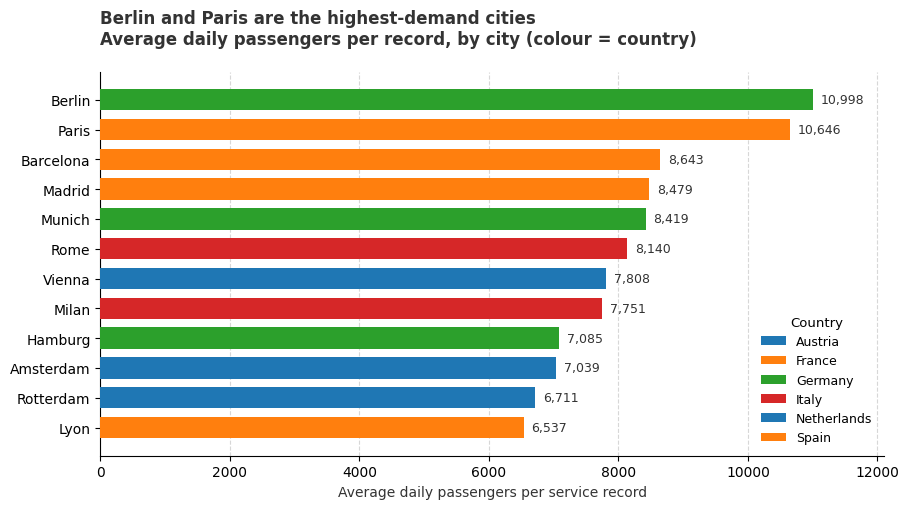

fig2 done


In [ ]:
"""FIG 2 - Comparison: average daily passengers by city, grouped by country."""
import os
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Ensure output directory exists
os.makedirs("figs", exist_ok=True)

# Group and calculate mean passengers per record by Country and City
c = (df.groupby(["Country", "City"])["Passengers"].mean()
       .reset_index().sort_values("Passengers", ascending=True))

# Define standard colors replacing prep.QUAL, prep.INK, etc.
countries = sorted(df["Country"].unique())
QUAL_COLORS = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']  # Qualitative color palette
INK_COLOR = '#333333'

cmap = {co: QUAL_COLORS[i % len(QUAL_COLORS)] for i, co in enumerate(countries)}
colors = c["Country"].map(cmap)

fig, ax = plt.subplots(figsize=(9.2, 5.2))
bars = ax.barh(c["City"], c["Passengers"], color=colors, zorder=3, height=0.72)

# Configure standard grid and clean boundaries
ax.grid(True, axis='x', linestyle='--', alpha=0.5, zorder=1)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_xlabel("Average daily passengers per service record", color=INK_COLOR, fontsize=10)
ax.set_ylabel("")

# Add text annotations next to each bar
for b, v in zip(bars, c["Passengers"]):
    ax.text(b.get_width() + 120, b.get_y() + b.get_height()/2,
            f"{v:,.0f}", va="center", ha="left", fontsize=9, color=INK_COLOR)

ax.margins(x=0.10)

# Render legend manually replacing prep custom elements
handles = [Patch(facecolor=cmap[co], label=co) for co in countries]
ax.legend(handles=handles, title="Country", loc="lower right",
          frameon=False, fontsize=9, title_fontsize=9.5)

# Native Matplotlib title implementation
plt.title("Berlin and Paris are the highest-demand cities\nAverage daily passengers per record, by city (colour = country)", pad=20, fontsize=12, fontweight='bold', color=INK_COLOR, loc='left')

plt.tight_layout()
plt.savefig("figs/fig2_comparison.png", bbox_inches='tight')
plt.show()
print("fig2 done")

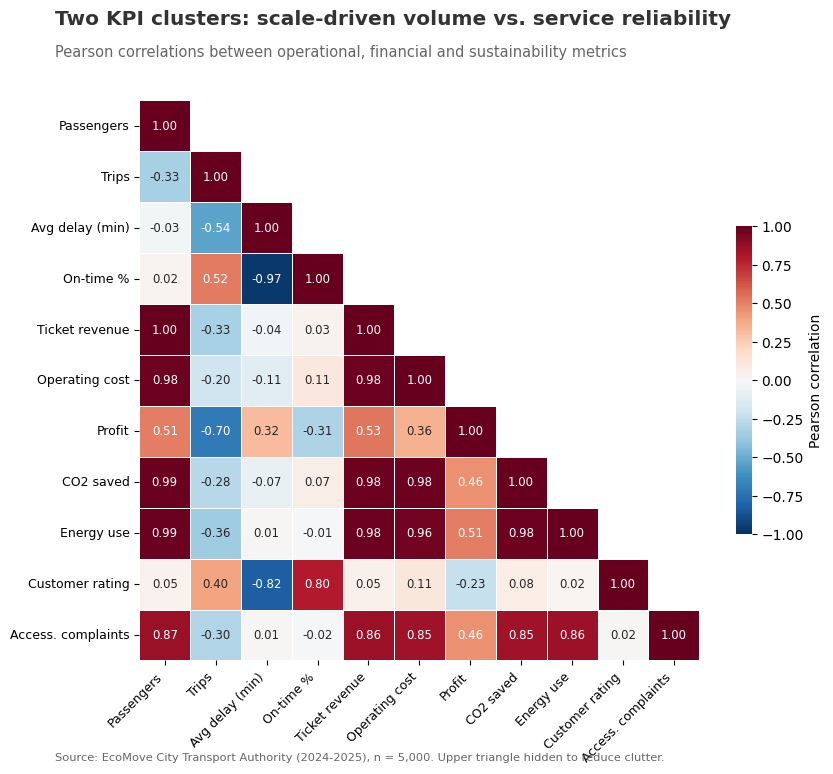

fig3 done


In [ ]:
"""FIG 3 - Relationship (overview): correlation heatmap of key numeric KPIs."""
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure output directory exists
os.makedirs("figs", exist_ok=True)

# Recalculate Profit_EUR because the raw data reload in the previous cell overwrote it
df['Profit_EUR'] = df['Ticket_Revenue_EUR'] - df['Operating_Cost_EUR']

# Define the variables locally instead of importing from prep
INK_COLOR = '#333333'
SUB_COLOR = '#666666'

# Specify target columns
cols = ["Passengers", "Trips", "Average_Delay_Minutes", "On_Time_Percentage",
        "Ticket_Revenue_EUR", "Operating_Cost_EUR", "Profit_EUR",
        "CO2_Saved_KG", "Energy_Consumption_KWh", "Customer_Rating",
        "Accessibility_Complaints"]

labels = ["Passengers", "Trips", "Avg delay (min)", "On-time %",
          "Ticket revenue", "Operating cost", "Profit",
          "CO2 saved", "Energy use", "Customer rating", "Access. complaints"]

corr = df[cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(9.0, 8.0))
fig.subplots_adjust(top=0.86, bottom=0.16, left=0.16, right=0.98)

sns.heatmap(corr, mask=mask, cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            annot=True, fmt=".2f", annot_kws={"size": 8.5},
            square=True, linewidths=0.6, linecolor="white",
            cbar_kws={u"shrink": 0.55, u"label": "Pearson correlation"},
            xticklabels=labels, yticklabels=labels, ax=ax)

ax.tick_params(labelsize=9)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
plt.setp(ax.get_yticklabels(), rotation=0)

# Text labels replacing the custom prep.titles or fig.text utilizing missing variables
fig.text(0.10, 0.955, "Two KPI clusters: scale-driven volume vs. service reliability",
         fontsize=14.5, fontweight="bold", color=INK_COLOR, ha="left")
fig.text(0.10, 0.915, "Pearson correlations between operational, financial and sustainability metrics",
         fontsize=10.5, color=SUB_COLOR, ha="left")
fig.text(0.10, 0.035,
         "Source: EcoMove City Transport Authority (2024-2025), n = 5,000. Upper triangle hidden to reduce clutter.",
         fontsize=8.2, color=SUB_COLOR, ha="left")

plt.savefig("figs/fig3_heatmap.png", bbox_inches='tight')
plt.show()
print("fig3 done")

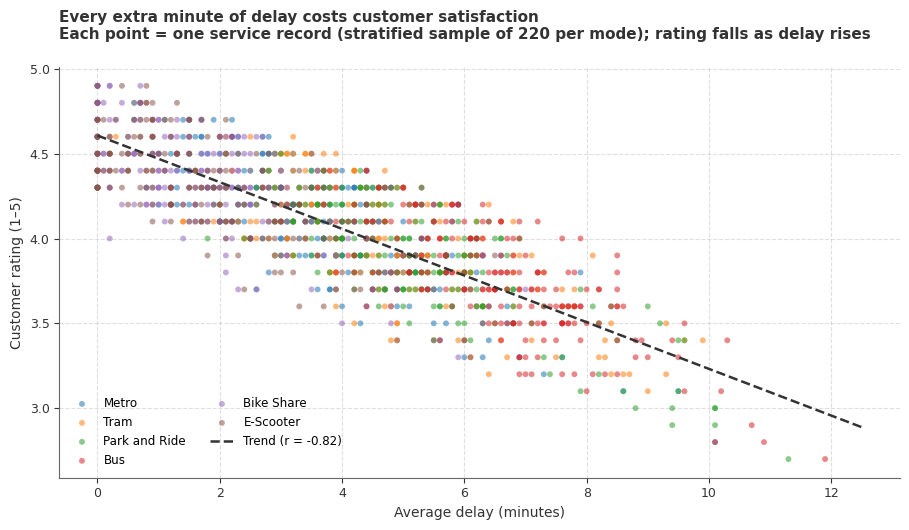

fig4 done


In [ ]:
"""FIG 4 - Relationship: delay vs customer rating, coloured by transport mode."""
import os
import matplotlib.pyplot as plt
import numpy as np

# Ensure output directory exists
os.makedirs("figs", exist_ok=True)

# Define the styling variables and palette locally instead of importing from prep
INK = '#333333'
SUB = '#666666'
QUAL = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']

modes = ["Metro", "Tram", "Park and Ride", "Bus", "Bike Share", "E-Scooter"]
cmap = {m: QUAL[i % len(QUAL)] for i, m in enumerate(modes)}

fig, ax = plt.subplots(figsize=(9.2, 5.4))

# Light sample per mode to avoid overplotting while keeping shape
for m in modes:
    d = df[df["Transport_Mode"] == m].sample(min(220, (df["Transport_Mode"] == m).sum()),
                                             random_state=1)
    ax.scatter(d["Average_Delay_Minutes"], d["Customer_Rating"],
               s=18, alpha=0.55, color=cmap[m], label=m, edgecolors="none", zorder=3)

# Overall trend line
z = np.polyfit(df["Average_Delay_Minutes"], df["Customer_Rating"], 1)
xs = np.linspace(df["Average_Delay_Minutes"].min(), df["Average_Delay_Minutes"].max(), 50)
ax.plot(xs, np.poly1d(z)(xs), color=INK, lw=1.8, ls="--", zorder=4,
        label=f"Trend (r = {df['Average_Delay_Minutes'].corr(df['Customer_Rating']):.2f})")

# Native clean_axes implementation (clean borders and apply custom grid lines)
ax.grid(True, which='both', linestyle='--', alpha=0.4, zorder=1)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color(SUB)
ax.spines["bottom"].set_color(SUB)
ax.tick_params(colors=INK, labelsize=9)

ax.set_xlabel("Average delay (minutes)", color=INK, fontsize=10)
ax.set_ylabel("Customer rating (1–5)", color=INK, fontsize=10)
ax.legend(loc="lower left", frameon=False, fontsize=8.6, ncol=2)

# Native Title Implementation
plt.title("Every extra minute of delay costs customer satisfaction\nEach point = one service record (stratified sample of 220 per mode); rating falls as delay rises",
          pad=20, fontsize=11, fontweight='bold', color=INK, loc='left')

plt.tight_layout()
plt.savefig("figs/fig4_scatter.png", bbox_inches='tight')
plt.show()
print("fig4 done")

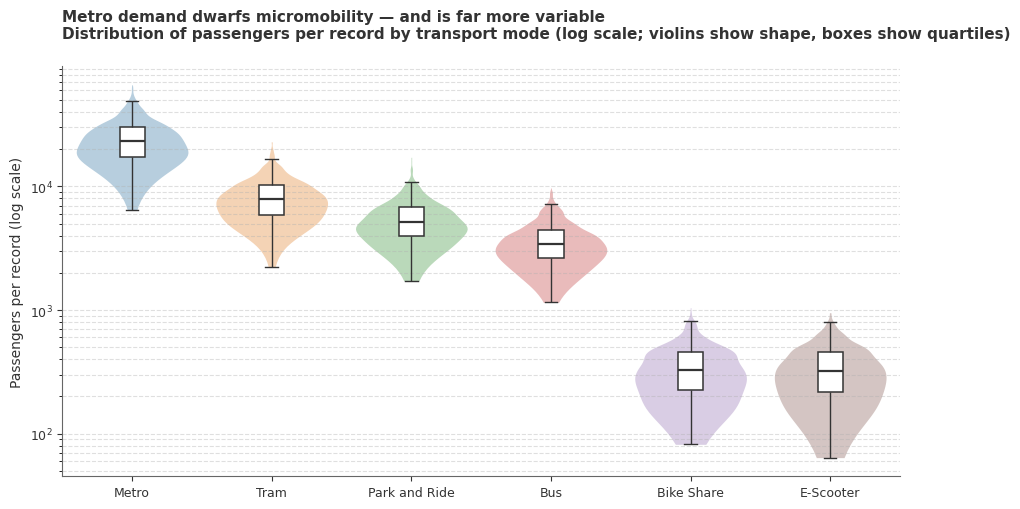

fig5 done


In [ ]:
"""FIG 5 - Distribution: passenger demand by transport mode (violin + box, log scale)."""
import os
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure output directory exists
os.makedirs("figs", exist_ok=True)

# Define the styling variables and palette locally instead of importing from prep
INK = '#333333'
SUB = '#666666'
QUAL = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']

# Use the already loaded df and find order
order = (df.groupby("Transport_Mode")["Passengers"].median()
           .sort_values(ascending=False).index.tolist())
pal = {m: QUAL[i % len(QUAL)] for i, m in enumerate(order)}

fig, ax = plt.subplots(figsize=(9.2, 5.2))

# Create violinplot
sns.violinplot(data=df, x="Transport_Mode", y="Passengers", order=order,
               hue="Transport_Mode", palette=pal, legend=False,
               inner=None, cut=0, linewidth=0, alpha=0.35, ax=ax)

# Create boxplot overlay
sns.boxplot(data=df, x="Transport_Mode", y="Passengers", order=order,
            width=0.18, showfliers=False, ax=ax,
            boxprops={"facecolor": "white", "edgecolor": INK, "linewidth": 1.1},
            medianprops={"color": INK, "linewidth": 1.6},
            whiskerprops={"color": INK}, capprops={"color": INK})

ax.set_yscale("log")
ax.set_ylabel("Passengers per record (log scale)", color=INK)
ax.set_xlabel("")

# Native clean_axes implementation (clean borders and apply custom grid lines)
ax.grid(True, which='both', axis='y', linestyle='--', alpha=0.4, zorder=1)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color(SUB)
ax.spines["bottom"].set_color(SUB)
ax.tick_params(colors=INK, labelsize=9)

# Native Title Implementation
plt.title("Metro demand dwarfs micromobility — and is far more variable\nDistribution of passengers per record by transport mode (log scale; violins show shape, boxes show quartiles)",
          pad=20, fontsize=11, fontweight='bold', color=INK, loc='left')

plt.tight_layout()
plt.savefig("figs/fig5_distribution.png", bbox_inches='tight')
plt.show()
print("fig5 done")

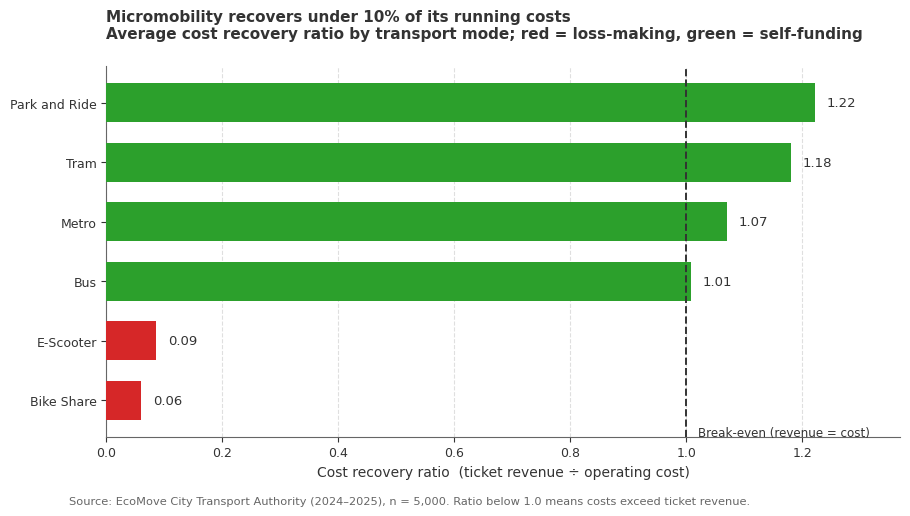

fig6 done


In [ ]:
"""FIG 6 - Performance indicator: cost recovery ratio by transport mode."""
import os
import matplotlib.pyplot as plt

# Ensure output directory exists
os.makedirs("figs", exist_ok=True)

# Recalculate Cost_Recovery column because the raw data reload in cell sXb0FwWyHmhJ overwrote it
df['Cost_Recovery'] = df['Ticket_Revenue_EUR'] / df['Operating_Cost_EUR']

# Define the styling variables and palette locally instead of importing from prep
INK = '#333333'
SUB = '#666666'
GOOD = '#2ca02c' # Green for self-funding
WARN = '#d62728' # Red for loss-making

r = (df.groupby("Transport_Mode")["Cost_Recovery"].mean()
       .sort_values().reset_index())
colors = [GOOD if v >= 1 else WARN for v in r["Cost_Recovery"]]

fig, ax = plt.subplots(figsize=(9.2, 5.0))
bars = ax.barh(r["Transport_Mode"], r["Cost_Recovery"], color=colors,
               zorder=3, height=0.66)
ax.axvline(1.0, color=INK, lw=1.4, ls="--", zorder=4)
ax.text(1.02, -0.6, "Break-even (revenue = cost)", fontsize=8.6, color=INK)

# Native clean_axes implementation (clean borders and apply custom grid lines)
ax.grid(True, which='both', axis='x', linestyle='--', alpha=0.4, zorder=1)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color(SUB)
ax.spines["bottom"].set_color(SUB)
ax.tick_params(colors=INK, labelsize=9)

ax.set_xlabel("Cost recovery ratio  (ticket revenue ÷ operating cost)", color=INK, fontsize=10)
ax.set_ylabel("")

for b, v in zip(bars, r["Cost_Recovery"]):
    ax.text(b.get_width() + 0.02, b.get_y() + b.get_height()/2,
            f"{v:.2f}", va="center", ha="left", fontsize=9.5, color=INK)
ax.margins(x=0.12)

# Native Title & Captions
plt.title("Micromobility recovers under 10% of its running costs\nAverage cost recovery ratio by transport mode; red = loss-making, green = self-funding",
          pad=20, fontsize=11, fontweight='bold', color=INK, loc='left')

fig.text(0.08, -0.02,
         "Source: EcoMove City Transport Authority (2024–2025), n = 5,000. Ratio below 1.0 means costs exceed ticket revenue.",
         fontsize=8.2, color=SUB, ha="left")

plt.tight_layout()
plt.savefig("figs/fig6_performance.png", bbox_inches='tight')
plt.show()
print("fig6 done")

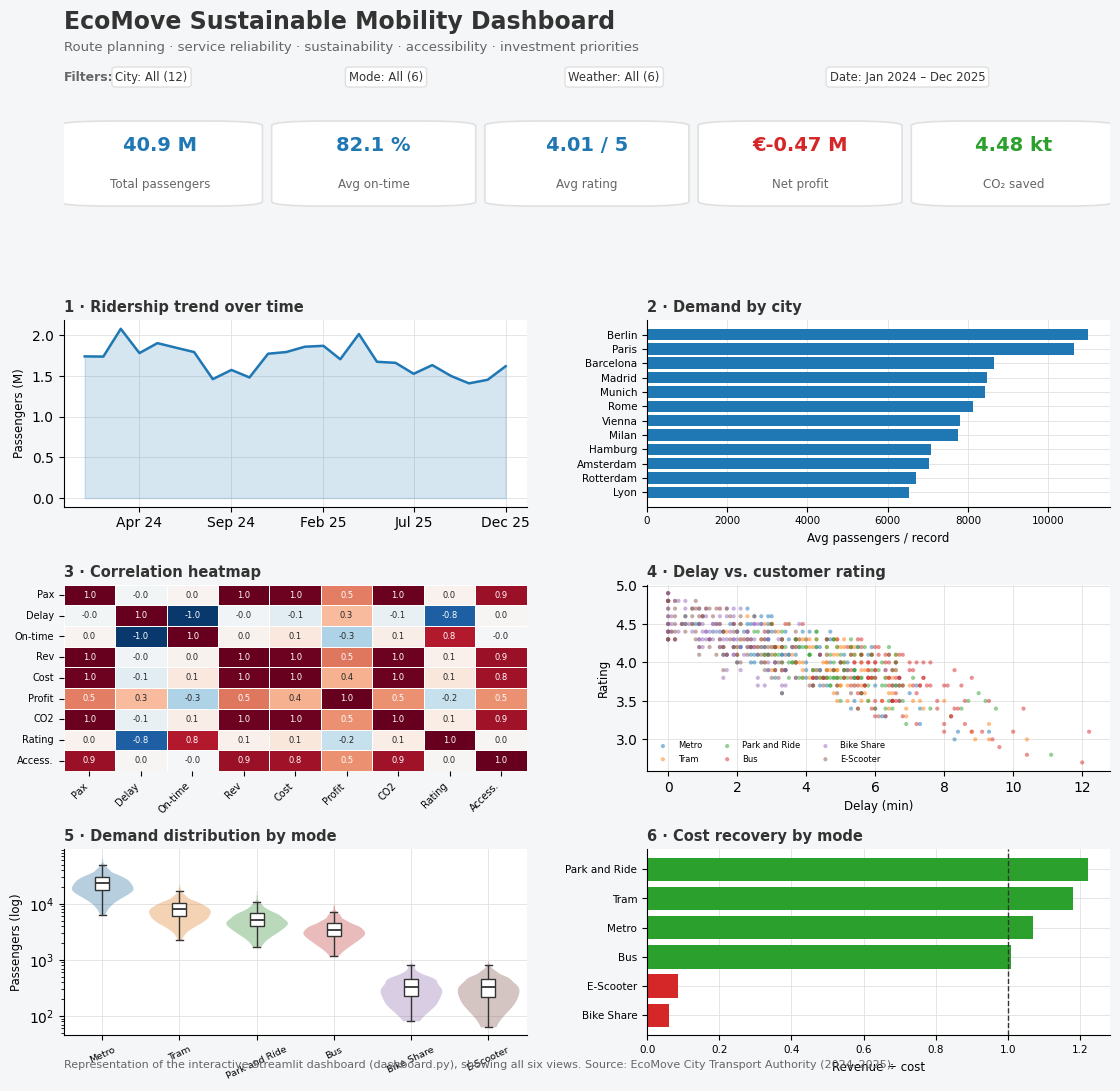

fig7 (6 views) rendered OK


In [ ]:
"""FIG 7 - Static composite mirroring the Streamlit dashboard: all SIX views."""
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.gridspec import GridSpec
from matplotlib.patches import FancyBboxPatch
import numpy as np
import seaborn as sns
import os

# Define variables locally that were previously imported from 'prep'
ACCENT = '#1f77b4'
WARN = '#d62728'
GOOD = '#2ca02c'
INK = '#333333'
SUB = '#666666'
GRID = '#e0e0e0'
QUAL = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']

# Re-load the dataset and compute necessary columns locally
df = pd.read_excel('/content/[5442] EcoMoveMobility.xlsx')
df['Date'] = pd.to_datetime(df['Date'], unit='D', origin='1899-12-30')
df['Month'] = df['Date'].dt.to_period('M').dt.to_timestamp()
df['Profit_EUR'] = df['Ticket_Revenue_EUR'] - df['Operating_Cost_EUR']
df['Cost_Recovery'] = df['Ticket_Revenue_EUR'] / df['Operating_Cost_EUR']

fig = plt.figure(figsize=(11.5, 11.0))
fig.patch.set_facecolor("#f4f6f8")
gs = GridSpec(3, 2, figure=fig, hspace=0.42, wspace=0.26,
              left=0.06, right=0.97, top=0.70, bottom=0.05)

# ---- Header ----
fig.text(0.06, 0.965, "EcoMove Sustainable Mobility Dashboard",
         fontsize=17, fontweight="bold", color=INK)
fig.text(0.06, 0.945, "Route planning · service reliability · sustainability · accessibility · investment priorities",
         fontsize=9.5, color=SUB)
# filter chips
chips = ["Filters:", "City: All (12)", "Mode: All (6)", "Weather: All (6)", "Date: Jan 2024 – Dec 2025"]
x = 0.06
for i, ch in enumerate(chips):
    if i == 0:
        fig.text(x, 0.918, ch, fontsize=9, color=SUB, fontweight="bold"); x += 0.045
        continue
    fig.text(x, 0.918, ch, fontsize=8.4, color=INK,
             bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=GRID, lw=1))
    x += 0.012 * len(ch) + 0.035

# ---- KPI cards ----
kpis = [("Total passengers", f"{df['Passengers'].sum()/1e6:,.1f} M", ACCENT),
        ("Avg on-time", f"{df['On_Time_Percentage'].mean():.1f} %", ACCENT),
        ("Avg rating", f"{df['Customer_Rating'].mean():.2f} / 5", ACCENT),
        ("Net profit", f"€{(df['Ticket_Revenue_EUR'].sum()-df['Operating_Cost_EUR'].sum())/1e6:,.2f} M", WARN),
        ("CO₂ saved", f"{df['CO2_Saved_KG'].sum()/1e6:,.2f} kt", GOOD)]
kax = fig.add_axes([0.06, 0.80, 0.91, 0.085]); kax.axis("off")
kax.set_xlim(0, 1); kax.set_ylim(0, 1)
n = len(kpis); w = 0.185; gap = (1 - n*w) / (n-1)
for i, (lab, val, col) in enumerate(kpis):
    xx = i*(w+gap)
    kax.add_patch(FancyBboxPatch((xx, 0.05), w, 0.9,
                  boxstyle="round,pad=0.005,rounding_size=0.05", fc="white", ec=GRID, lw=1.2))
    kax.text(xx+w/2, 0.64, val, fontsize=14, fontweight="bold", color=col, ha="center")
    kax.text(xx+w/2, 0.24, lab, fontsize=8.6, color=SUB, ha="center")

modes_order = ["Metro", "Tram", "Park and Ride", "Bus", "Bike Share", "E-Scooter"]
cmap = {m: QUAL[i] for i, m in enumerate(modes_order)}

def style(ax, title):
    ax.set_title(title, fontsize=10.5, fontweight="bold", loc="left", color=INK, pad=6)
    ax.set_facecolor("white")
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    ax.grid(axis="both", color=GRID, lw=0.6); ax.set_axisbelow(True)

# Panel 1: ridership trend
ax = fig.add_subplot(gs[0, 0])
trend = df.groupby("Month")["Passengers"].sum().reset_index()
ax.fill_between(trend["Month"], trend["Passengers"]/1e6, color=ACCENT, alpha=0.18)
ax.plot(trend["Month"], trend["Passengers"]/1e6, color=ACCENT, lw=1.8)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=5))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
ax.set_ylabel("Passengers (M)", fontsize=8.5)
style(ax, "1 · Ridership trend over time")

# Panel 2: demand by city
ax = fig.add_subplot(gs[0, 1])
city = df.groupby("City")["Passengers"].mean().sort_values()
ax.barh(city.index, city.values, color=ACCENT)
ax.tick_params(labelsize=7.5); ax.set_xlabel("Avg passengers / record", fontsize=8.5)
style(ax, "2 · Demand by city")

# Panel 3: correlation heatmap
ax = fig.add_subplot(gs[1, 0])
cols = ["Passengers", "Average_Delay_Minutes", "On_Time_Percentage", "Ticket_Revenue_EUR",
        "Operating_Cost_EUR", "Profit_EUR", "CO2_Saved_KG", "Customer_Rating", "Accessibility_Complaints"]
short = ["Pax", "Delay", "On-time", "Rev", "Cost", "Profit", "CO2", "Rating", "Access."]
corr = df[cols].corr()
sns.heatmap(corr, cmap="RdBu_r", vmin=-1, vmax=1, center=0, annot=True, fmt=".1f",
            annot_kws={"size": 6}, cbar=False, square=False,
            xticklabels=short, yticklabels=short, linewidths=0.4, linecolor="white", ax=ax)
ax.tick_params(labelsize=7)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax.set_title("3 · Correlation heatmap", fontsize=10.5, fontweight="bold", loc="left", color=INK, pad=6)

# Panel 4: delay vs rating scatter
ax = fig.add_subplot(gs[1, 1])
for i, m in enumerate(modes_order):
    d = df[df["Transport_Mode"] == m].sample(120, random_state=2)
    ax.scatter(d["Average_Delay_Minutes"], d["Customer_Rating"], s=9, alpha=0.5,
               color=QUAL[i], label=m, edgecolors="none")
ax.set_xlabel("Delay (min)", fontsize=8.5); ax.set_ylabel("Rating", fontsize=8.5)
ax.legend(fontsize=6, ncol=3, frameon=False, loc="lower left")
style(ax, "4 · Delay vs. customer rating")

# Panel 5: distribution violin/box by mode
ax = fig.add_subplot(gs[2, 0])
order5 = df.groupby("Transport_Mode")["Passengers"].median().sort_values(ascending=False).index.tolist()
pal5 = {m: QUAL[modes_order.index(m)] for m in order5}
sns.violinplot(data=df, x="Transport_Mode", y="Passengers", order=order5, hue="Transport_Mode",
               palette=pal5, legend=False, inner=None, cut=0, linewidth=0, alpha=0.35, ax=ax)
sns.boxplot(data=df, x="Transport_Mode", y="Passengers", order=order5, width=0.18, showfliers=False,
            boxprops={"facecolor": "white", "edgecolor": INK, "linewidth": 1.0},
            medianprops={"color": INK, "linewidth": 1.3},
            whiskerprops={"color": INK}, capprops={"color": INK}, ax=ax)
ax.set_yscale("log"); ax.set_ylabel("Passengers (log)", fontsize=8.5); ax.set_xlabel("")
ax.tick_params(axis="x", labelsize=6.8, rotation=25)
style(ax, "5 · Demand distribution by mode")

# Panel 6: cost recovery
ax = fig.add_subplot(gs[2, 1])
rec = df.groupby("Transport_Mode")["Cost_Recovery"].mean().sort_values()
ax.barh(rec.index, rec.values, color=[GOOD if v >= 1 else WARN for v in rec.values])
ax.axvline(1, color=INK, ls="--", lw=1)
ax.tick_params(labelsize=7.5); ax.set_xlabel("Revenue ÷ cost", fontsize=8.5)
style(ax, "6 · Cost recovery by mode")

fig.text(0.06, 0.02, "Representation of the interactive Streamlit dashboard (dashboard.py), showing all six views. "
         "Source: EcoMove City Transport Authority (2024–2025).", fontsize=8, color=SUB)
os.makedirs("figs", exist_ok=True)
plt.savefig("figs/fig7_dashboard.png", dpi=200, facecolor=fig.get_facecolor())
plt.show()
print("fig7 (6 views) rendered OK")